In [11]:
import sklearn # import a package
import numpy as np # import a package under an alias
import matplotlib.pyplot as plt # import a submodule with an alias
from sklearn import linear_model # import a submodule
from os import mkdir # import a peculiar function
import string
import time

Question 1

In [26]:
alphabet = string.ascii_lowercase
print(alphabet[2::3], '\n', 
    alphabet[21::2], '\n',
    alphabet[25:18:-2])

cfilorux 
 vxz 
 zxvt


Question 2

In [39]:
string1 = " XHEC DataScience for Business "
string1 = string1.lower()
string1 = string1.strip()
string1 = string1.replace('e', 'E')
string1

'xhEc datasciEncE for businEss'

Question 3

In [49]:
print(f"Pi vaut : {np.pi:.9f}")

Pi vaut : 3.141592654


Question 4

In [54]:
s = 'Hello World!!'
s = s.lower()
compteur = {}
for el in s:
    if el in compteur:
        compteur[el] +=1
    else:
        compteur[el] = 1
print(compteur)

{'h': 1, 'e': 1, 'l': 3, 'o': 2, ' ': 1, 'w': 1, 'r': 1, 'd': 1, '!': 2}


Question 5

In [57]:
calcul = 0.1+100-100
print(calcul == 0.1)
print(np.allclose(calcul, 0.1))

False
True


Computers store numbers in binary, and fractions like 0.1 cannot be represented perfectly. The operations + 100 - 100 introduce a tiny rounding error.

Question 6

In [258]:
squares = [i**2 for i in range(1,12)]
print('Squares list :', squares)

print('np squares :', np.arange(1,12)**2)

Squares list : [1, 4, 9, 16, 25, 36, 49, 64, 81, 100, 121]
np squares : [  1   4   9  16  25  36  49  64  81 100 121]


We should use Numpy arrays because they are much faster than native Python for loops. Numpy applies operations to the whole array at once (this is called vectorization), making it very fast for large datasets.

Question 7

In [72]:
print(np.arange(2,15,3))
print(np.linspace(0,1,15))

[ 2  5  8 11 14]
[0.         0.07142857 0.14285714 0.21428571 0.28571429 0.35714286
 0.42857143 0.5        0.57142857 0.64285714 0.71428571 0.78571429
 0.85714286 0.92857143 1.        ]


Question 8

In [21]:
%%timeit

n = 1000000
result = 1
for k in range(1,n):
    result = result*(4*k**2)/((4*k**2)-1)
result = 2*result

87.5 ms ± 1.93 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [22]:
%%timeit  
n = 1000000
k = np.arange(1,n)
produit = 2*np.prod((4*k**2)/((4*k**2)-1))


4.45 ms ± 38.4 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [23]:
#without timeit
n = 1000000
t0 = time.time()
result = 1
for k in range(1,n):
    result = result*(4*k**2)/((4*k**2)-1)
result = 2*result
looptime = time.time()-t0

n = 1000000
t1 = time.time()
k = np.arange(1,n)
produit = 2*np.prod((4*k**2)/((4*k**2)-1))
nptime = time.time()-t1

In [24]:
print(f'Pour le loop : le résultat est {result :.9f} et le temps {looptime:.3f}')
print(f'Pour le np.arange : le résultat est {produit :.9f} et le temps {nptime:.3f}')

Pour le loop : le résultat est 3.141591868 et le temps 0.164
Pour le np.arange : le résultat est 3.141591868 et le temps 0.010


%timeit is better than time.time() because it runs the code multiple times and calculates the average execution time. 
time.time() only measures a single run, which can be affected by background processes running on the computer.

Question 9

In [13]:
vect = np.arange(5)
print('vect :', vect)

dotprod = np.dot(vect, np.ones(5))
print('dot product :', dotprod)

Shape1 = np.shape(vect) ## Vect is a vector and has 1 dimension
print('Shape vect :', Shape1)

print('vect.T :', vect.T)  ### .T does not change anything

Shape2 = np.shape(vect.T) ### Shape vect == shape vect.T
print('Shape vect.T :', Shape2)


vect : [0 1 2 3 4]
dot product : 10.0
Shape vect : (5,)
vect.T : [0 1 2 3 4]
Shape vect.T : (5,)


Question 10

In [256]:
M = np.arange(12).reshape(2, 6)
print('M :\n', M, '\n')  #### Reshapes vector of 12 elements in a matrix 2*6 elements

print('M[:, ::3] :\n', M[:, ::3], '\n') ### Takes all rows and every 3rd column starting by column 0

forme = np.shape(np.arange(3)[np.newaxis, :])
print('Forme avec newaxis :\n', forme, '\n')

print(np.arange(3)[np.newaxis, :] * np.arange(4)[:, np.newaxis]) ##  it virtually reshapes the elements so we can perform operations on them.
                                                                ### Going from the right to the left, it compares the dimension of each element and if they're =,
                                                                ### it's okay and if one of them =1, it extend this dimension to the same dimension of the other element

M :
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]] 

M[:, ::3] :
 [[0 3]
 [6 9]] 

Forme avec newaxis :
 (1, 3) 

[[0 0 0]
 [0 1 2]
 [0 2 4]
 [0 3 6]]


Question 11

In [253]:
Mnew = np.random.uniform(-1, 1, size = (5, 6))
print('M initial :\n', Mnew)

Mnew[:,::2] = Mnew[:,::2]-2*Mnew[:, 1::2]   #### even column = even column - 2*uneven column

print('M final :\n', Mnew)


M initial :
 [[ 0.42137389  0.49986533  0.64782853 -0.48791921 -0.0047074  -0.98926653]
 [-0.42769906  0.65702241  0.81704179  0.61049924  0.93256405 -0.10057964]
 [-0.44265325 -0.54048171 -0.50717513  0.38320489 -0.13483136  0.25801692]
 [ 0.45277017  0.21035753 -0.94670095 -0.25967495 -0.71235313  0.02443294]
 [-0.04109105 -0.51174788 -0.64640842 -0.87017776  0.00734555 -0.469103  ]]
M final :
 [[-0.57835678  0.49986533  1.62366694 -0.48791921  1.97382566 -0.98926653]
 [-1.74174388  0.65702241 -0.40395669  0.61049924  1.13372332 -0.10057964]
 [ 0.63831017 -0.54048171 -1.27358491  0.38320489 -0.6508652   0.25801692]
 [ 0.03205511  0.21035753 -0.42735106 -0.25967495 -0.76121902  0.02443294]
 [ 0.9824047  -0.51174788  1.0939471  -0.87017776  0.94555155 -0.469103  ]]


Question 12

In [252]:
Mnew[Mnew<0] = 0   ### boolean mask where all neg values are now = 0
print('M without negative values : \n', Mnew, '\n')

Moy = Mnew.mean(axis = 1) ## takes mean of each row

print('M column-centered :\n', Mnew-Moy[:, np.newaxis])

M without negative values : 
 [[1.01787218 0.         0.         0.48933948 0.         0.97071758]
 [1.6715     0.         0.         0.44346992 0.         0.93270199]
 [0.         0.67976991 0.19103888 0.         2.38409489 0.        ]
 [0.         0.42043369 0.         0.35844163 0.         0.        ]
 [0.52352953 0.         1.39893023 0.         0.         0.        ]] 

M column-centered :
 [[ 0.60488398 -0.41298821 -0.41298821  0.07635127 -0.41298821  0.55772937]
 [ 1.16355468 -0.50794532 -0.50794532 -0.0644754  -0.50794532  0.42475667]
 [-0.54248395  0.13728596 -0.35144507 -0.54248395  1.84161095 -0.54248395]
 [-0.12981255  0.29062113 -0.12981255  0.22862907 -0.12981255 -0.12981255]
 [ 0.20311957 -0.32040996  1.07852027 -0.32040996 -0.32040996 -0.32040996]]


Question 13

In [ ]:
Matrice = np.random.uniform(-1, 1, size = (5, 10))
G = np.dot(Matrice.T, Matrice)
print('Is the matrix symetric? ', np.allclose(G, G.T)) ### Symetric
print('Is the matrix semi definite positive?', np.all(np.linalg.eigvalsh(G)>=-1e-10)) ### Semi def positive

print('Rank =', np.linalg.matrix_rank(G))
print('Euclidian Norm =', np.linalg.matrix_norm(G))
print('Spectral Norm =', np.linalg.matrix_norm(G, ord = 2))
print('Std of columns : ', np.std(G, axis = 0)) ### standard dev of column (axis 0)

Is the matrix symetric?  True
Is the matrix semi definite positive? True
Rank = 5
Euclidian Norm = 7.206643387577597
Spectral Norm = 4.827126650250096
Std of columns :  [0.50725398 0.52382469 0.64719597 0.78652951 0.65475109 0.88540227
 0.68571371 0.35035431 0.36766815 1.1730882 ]


The eigenvalues are NOT strictly positive. Because the initial matrix M is 5x10, the maximum rank of G is 5. Since G is a 10x10 matrix, it means the 5 other eigenvalues are exactly 0. So the matrix is only semi-definite positive.

Question 14

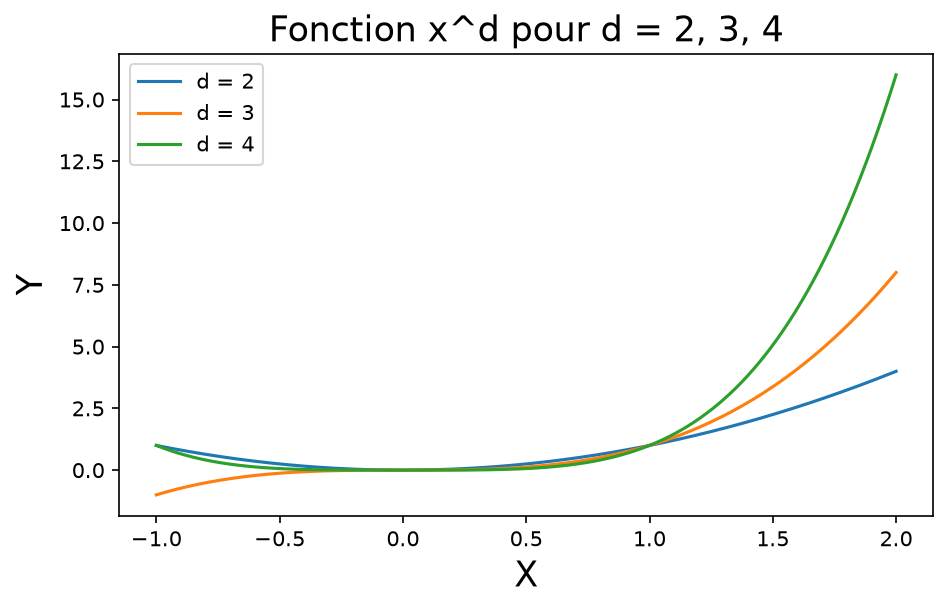

In [239]:
x = np.linspace(-1,2,500)
d = np.array([2,3,4])

y = x[:, np.newaxis]**d
fig, ax = plt.subplots(figsize=(7, 4), dpi=150)  # dpi par défaut = 100
ax.plot(x, y)
##plt.plot(x,y)
plt.xlabel('X', size = 17)
plt.ylabel('Y', size = 17)
plt.legend([f"d = {di}" for di in d])
plt.title('Fonction x^d pour d = 2, 3, 4', size = 17)
plt.show()

Question 15

In [ ]:
array1 = np.arange(1, 20, 2)
print(array1)

mean = np.mean(array1) #### the mean of  array is a number, not a vector
arraycentered = array1 - mean 
print(arraycentered)


array0to11 = np.arange(12).reshape(3,4)  ## takes array from 0 to 11 (12) and reshape it
print('\n array 0 to 11:', array0to11)
print('\n test [1,2] : 4*1+2=6. Matrix answer : ', array0to11[1, 2]) 

[ 1  3  5  7  9 11 13 15 17 19]
[-9. -7. -5. -3. -1.  1.  3.  5.  7.  9.]

 array 0 to 11: [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

test [1,2] : 4*1+2=6. Matrix answer :  6


Question 16

In [260]:
meancolwise = np.mean(array0to11, axis=0)
arraycolcentered = array0to11 - meancolwise
print('Array - column-wise mean :\n', arraycolcentered)

meanrowwise = np.mean(arraycolcentered, axis=1)
meanrowwise = meanrowwise[:, None]
arrayrowcentered = arraycolcentered - meanrowwise
print('Array - row-wise mean :\n', arrayrowcentered)

Array - column-wise mean :
 [[-4. -4. -4. -4.]
 [ 0.  0.  0.  0.]
 [ 4.  4.  4.  4.]]
Array - row-wise mean :
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


Question 17

In [288]:
arr5 = np.arange(1,6)
arr3 = np.arange(1,4)

arr3x5 = arr3[:, np.newaxis] * arr5  ### broadcasting
print('Matrix 3x5 : \n', arr3x5)

print('\n Test for i = 2 and j = 4 :\n - 2 x 4 = 8 \n - Matrix result : ', arr3x5[1, 3])

Matrix 3x5 : 
 [[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]]

 Test for i = 2 and j = 4 :
 - 2 x 4 = 8 
 - Matrix result :  8


Question 18. Integers in Python are immutable: you cannot modify an existing `int` object in memory. It only rebinds the label `a` so that it points to this new object. The other objects are not affected by the a += 1.

In [286]:
a = 1000
print('Initial id(a):', id(a))

b = 1000
print('Initial id(b):', id(b))

c = a
print('Initial id(c):', id(c), '\n')

a += 1
print('a =', a, ' new id(a) :', id(a))    #### New id
print('b =', b, ' new id(b) :', id(b))    #### Remains unchanged
print('c =', c, ' new id(c) :', id(c))    #### Remains Unchanged

Initial id(a): 1873008947600
Initial id(b): 1873012491600
Initial id(c): 1873008947600 

a = 1001  new id(a) : 1873012496304
b = 1000  new id(b) : 1873012491600
c = 1000  new id(c) : 1873008947600


Question 19. As numpy objects are mutable, we can modify direct their content in the memory, meaning that we do not need to rebind a label to point to a new object.

In [ ]:
a = np.array([0, 1])
print('Initial id(a):', id(a))   

b = np.array([0, 1])
print('Initial id(b):', id(b))

c = a
print('Initial id(c):', id(c), '\n')

a += 1
print('a =', a, ' new id(a) :', id(a))    ####  Unchanged
print('b =', b, ' new id(b) :', id(b))    ####  Unchanged
print('c =', c, ' new id(c) :', id(c))    ####  Unchanged


Initial id(a): 1873012272624
Initial id(b): 1873012270512
Initial id(c): 1873012272624 

a = [1 2]  new id(a) : 1873012272624
b = [0 1]  new id(b) : 1873012270512
c = [1 2]  new id(c) : 1873012272624


Question 20. This depend on the mutability of the type we use. When a is an integer, a always points toward 1 in the memory (value not changed in memory) while f(a) points to 2. However, when a array, its value is modified by the function in the memory so it becomes [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.] but a still points toward the same point in the memory.

In [33]:
def f(a):
    a += 1
    print(a)

a = 1
print('Initial id(a):', id(a))   
f(a)
print('Value of a after f:', a)
print('New id(a) :', id(a))
print()

a = np.ones(10)
print('Initial id(a):', id(a))   
f(a)
print('Value of a (np) after f:', a)
print('New id(a) :', id(a))

Initial id(a): 4315915616
2
Value of a after f: 1
New id(a) : 4315915616

Initial id(a): 6103652880
[2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
Value of a (np) after f: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
New id(a) : 6103652880


Question 21. a = b changes the element in memory toward which a was pointing and points now at the same one as b. c[:] = d takes the datas of d and puts them into the object in memory where c is pointing so c and d are not the pointing to same object.

In [27]:
a = np.zeros(10)
print('Initial id(a):', id(a))
b = np.ones(10)
print('Initial id(b):',id(b))
a = b
print('a =', a, ' new id(a) :', id(a), '\n')

a = np.zeros(10)
print('Initial id(a):', id(a))
b = np.ones(10)
print('Initial id(b):', id(b))
##c = a
a[:] = b
##c[0]= 12
##print(a)
##print(b)
print('a =', a, ' new id(a) :', id(a),'\n')

print('Initial id(a):', id(a))
a = a + 1
print("After a = a + 1, id(a) : ", id(a))

a += 1
print("After a += 1, id(a) :", id(a))

Initial id(a): 6103653648
Initial id(b): 6103652496
a = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]  new id(a) : 6103652496 

Initial id(a): 6103652976
Initial id(b): 6103655856
a = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]  new id(a) : 6103652976 

Initial id(a): 6103652976
After a = a + 1, id(a) : 6103652880
After a += 1, id(a) : 6103652880
